# Mall Customers — the nine-step KDD process

A descriptive segmentation study using K-Means on Kaggle's
[Mall Customers dataset, version 1](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python).
The nine headings follow the detailed process in
[Fayyad, Piatetsky-Shapiro and Smyth (1996), pp. 42–43](https://www.ai.rug.nl/ki2/literature/kdd-fayyad-shapiro-smyth.pdf).
The task-specific choices below instantiate that process for this small table.
Python 3.11; random seed 42. Run all cells in order from within this repository.

A [two-round methodological review](../reports/review_log.md) distinguishes
reproducible description from validated knowledge. Sensitivity analyses are
diagnostics; the original representation, primary k-selection rule and model
remain fixed rather than selected again to improve reported metrics.

## 1. Understand the domain and define discovery goals

A hypothetical mall analyst wants a compact description of spending-score patterns
at different income levels. Discover groups of customers with similar observed
income and spending score, then describe group sizes and typical values. This is
not supervised prediction: no true segment labels, campaign outcomes, profit,
transaction history or dated follow-up are available. The source's spending-score
construction and sampling frame are not established by the CSV.

Success for this study means a reproducible partition, transparent feature and
cluster-count choices, readable numerical profiles, and an honest assessment of
internal separation and perturbation stability. There is no business-approved
silhouette target or evidence that these groups improve marketing outcomes.
Do not interpret higher income or spending score as greater customer worth.
Novelty and usefulness require a domain owner's review, not just a metric.

**Claim boundary and acceptance.** The technical deliverable can establish what
this fixed two-feature partition looks like and how it changes under limited
perturbations. It cannot establish that Spending Score is a valid measure of
spending behavior, that five real customer types exist, or that any group should
receive a particular intervention. The hypothetical analyst's acceptance and
score provenance remain unresolved; numerical reproducibility is not their proxy.

The review therefore accepts a **conditional descriptive partition**, not a
validated behavioral taxonomy: changing score weight can change the preferred
cluster count, while repeatability at fixed k can remain high. These statements
answer different questions and must appear together in the final claim record.

In [1]:
from pathlib import Path
import hashlib
import io
import json
import platform
import sys
import urllib.request
import zipfile
from importlib.metadata import version

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import linear_sum_assignment
from sklearn.metrics.cluster import contingency_matrix
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

SEED = 42
here = Path.cwd().resolve()
PROJECT = next((p for base in [here, *here.parents] for p in [base / "KDD", base]
                if p.name == "KDD" and (p / "data").is_dir()), None)
assert PROJECT is not None, "Run within this repository."
sys.path.insert(0, str(PROJECT / "src"))
from mall import DATASET, SOURCE_URL, DOWNLOAD_URL, SHA256, FEATURES, feature_frame, make_pipeline, assign_customers, representation_sensitivity
RAW = PROJECT / "data/raw/Mall_Customers.csv"
REPORTS, OUTPUTS = PROJECT / "reports", PROJECT / "outputs"
REPORTS.mkdir(exist_ok=True)
OUTPUTS.mkdir(exist_ok=True)
print("Python:", platform.python_version())

Python: 3.11.17


## 2. Create the target dataset

Retrieve the versioned Kaggle CSV, verify its SHA-256, and use all 200 rows. Here
“target dataset” means the table selected for discovery, not a supervised target.
Select annual income (source units `k$`) and spending score (`1–100`) as the two
clustering features. Retain customer ID for joining assignments to source rows;
retain age and the source's gender labels for descriptive profiling only.
No joins, row sampling, synthetic customer generation for training, or target
encoding are needed. Excluding age/gender defines a two-variable question; it is
not a claim that those fields lack information or that the result is fair.

**Selection rationale and lineage.** Income/score clustering is a narrow question,
not a complete customer segmentation. The two-dimensional view was chosen for
interpretability, not because a feature-selection experiment established optimality.
The supplied age/gender fields do not become independent validation labels merely
because they were excluded from fitting. Record what is and is not known about
each field instead of inventing a geographic population, income currency basis,
observation period or score definition.

Four observations repeat an earlier income/score profile, but no complete non-ID
record is duplicated. Retain distinct IDs; deleting equal projected points would
alter the empirical weighting without evidence of duplicate persons. Conversely,
distinct IDs cannot establish independent sampling or household independence.

In [2]:
if not RAW.exists():
    RAW.parent.mkdir(parents=True, exist_ok=True)
    request = urllib.request.Request(DOWNLOAD_URL, headers={"User-Agent":"mall-kdd/1.0"})
    with urllib.request.urlopen(request, timeout=120) as response:
        archive = response.read()
    with zipfile.ZipFile(io.BytesIO(archive)) as z:
        payload = z.read("Mall_Customers.csv")
    assert hashlib.sha256(payload).hexdigest() == SHA256, "Unexpected dataset bytes."
    RAW.write_bytes(payload)
assert hashlib.sha256(RAW.read_bytes()).hexdigest() == SHA256
raw = pd.read_csv(RAW)
assert raw.shape == (200,5)
assert set(raw.columns) == {"CustomerID", "Gender", "Age", *FEATURES}
X = raw[FEATURES].copy()
print("Selected records/features:", X.shape)
print("Source columns:", list(raw.columns))
lineage = pd.DataFrame([
    {"field":"CustomerID","role":"join only","known":"source identifier","unverified":"person identity and sampling independence"},
    {"field":"Gender","role":"descriptive only","known":"source categories Male/Female","unverified":"collection method and completeness of categories"},
    {"field":"Age","role":"descriptive only","known":"source Age column","unverified":"observation date and source population"},
    {"field":FEATURES[0],"role":"clustering","known":"source k$ units","unverified":"currency basis, measurement period and reliability"},
    {"field":FEATURES[1],"role":"clustering","known":"source 1-100 score","unverified":"formula, inputs, interval scale and cross-customer comparability"},
])
lineage.to_csv(REPORTS / "feature_lineage.csv",index=False)


Selected records/features: (200, 2)
Source columns: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


## 3. Clean and preprocess

Audit missingness, row/ID duplication, types, observed ranges and repeated
clustering profiles. Fail clearly for corrupt or incomplete features rather than
invent values; the verified source needs no imputation or row deletion. Distinct
IDs with identical feature values need not be duplicate people. Check age and
gender only for source integrity, without encoding them into the distance metric.
There is no date column, so temporal change cannot be assessed. Retain high-income
observations; being unusual does not alone establish data error.

Schema validity is not measurement validity. A bounded integer score can still be
ordinal, derived from other columns, stale, or incomparable between customers.
Record duplicate/selection accounting and IQR flags; retain flagged observations
because no source evidence establishes an error. A checksum establishes the bytes
used, not that those bytes describe reliable or representative customers.

To check influence rather than silently edit the sample, repeat only the fixed
reference k after excluding income IQR flags. Refit the scaler on that subset and
compare its assignments on the original records. This is a deterministic influence
diagnostic, not a new cleaning policy, independent test or optimized alternative.

In [3]:
assert not raw.isna().any().any()
assert raw.CustomerID.is_unique and raw.CustomerID.notna().all()
assert not raw.duplicated().any()
assert raw.Age.between(0,120).all() and raw.Age.mod(1).eq(0).all()
assert raw.Gender.isin(["Male","Female"]).all()
X = feature_frame(X)
quality = pd.DataFrame({"dtype":raw.dtypes.astype(str), "missing":raw.isna().sum(), "distinct":raw.nunique()})
quality.to_csv(REPORTS / "data_quality.csv")
display(quality)
print("Duplicate complete non-ID records:", raw.drop(columns="CustomerID").duplicated().sum())
print("Repeated two-feature profiles (distinct IDs retained):", X.duplicated().sum())
display(raw[["Age",*FEATURES]].describe())
assert pd.to_numeric(raw.CustomerID,errors="raise").gt(0).all() and raw.CustomerID.mod(1).eq(0).all()
quality_summary = {"source_rows":len(raw),"analysis_rows":len(X),"rows_removed":0,
                   "missing_cells":int(raw.isna().sum().sum()),"duplicate_rows":int(raw.duplicated().sum()),
                   "duplicate_non_id_records":int(raw.drop(columns="CustomerID").duplicated().sum()),
                   "repeated_two_feature_profiles":int(X.duplicated().sum()),
                   "income_is_sorted_in_source":bool(raw[FEATURES[0]].is_monotonic_increasing)}
for column in FEATURES:
    q1,q3 = X[column].quantile([.25,.75]); iqr=q3-q1
    quality_summary[f"{column}_iqr_flags"] = int(((X[column]<q1-1.5*iqr)|(X[column]>q3+1.5*iqr)).sum())
(REPORTS / "quality_summary.json").write_text(json.dumps(quality_summary,indent=2)+"\n")
print(quality_summary)

multiplicity = X.groupby(FEATURES).size()
quality_summary["distinct_two_feature_profiles"] = int(len(multiplicity))
quality_summary["profiles_with_multiple_ids"] = int(multiplicity.gt(1).sum())
quality_summary["customers_in_repeated_profiles"] = int(multiplicity[multiplicity.gt(1)].sum())
(REPORTS / "quality_summary.json").write_text(json.dumps(quality_summary,indent=2)+"\n")


,dtype,missing,distinct
CustomerID,int64,0,200
Gender,str,0,2
Age,int64,0,51
Annual Income (k$),int64,0,64
Spending Score (1-100),int64,0,84


Duplicate complete non-ID records: 0
Repeated two-feature profiles (distinct IDs retained): 4


,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


{'source_rows': 200, 'analysis_rows': 200, 'rows_removed': 0, 'missing_cells': 0, 'duplicate_rows': 0, 'duplicate_non_id_records': 0, 'repeated_two_feature_profiles': 4, 'income_is_sorted_in_source': True, 'Annual Income (k$)_iqr_flags': 2, 'Spending Score (1-100)_iqr_flags': 0}


416

## 4. Reduce and transform the representation

Reduce the five source columns to the two selected numeric features. Standardize
each to zero mean/unit population variance so each axis contributes on a comparable
scale to Euclidean distance. This is an explicit weighting assumption, not an
invariance guarantee; different scaling or including age would change the question.
No PCA is needed for two interpretable dimensions. Keep validation and scaling
inside the saved pipeline; use inverse-transformed centroids for interpretation.

This is exploratory discovery on the entire table, so the scaler and final model
are fitted to all rows. Internal indices used to select `k` are in-sample diagnostics,
not unbiased external validation. There is no claimed train/test accuracy. In
subsampling checks, refit the scaler on each subsample. New customers are transformed
using the stored scaler without refitting.

**Weighting audit.** Standardization makes the objective proportional to
`(income difference / income SD)^2 + (score difference / score SD)^2`. It gives
equal standardized-axis weights, not equal economic significance. After fitting
the reference, inspect fixed score contributions 0.5, 1 and 2 by multiplying its
standardized coordinate by the square root of that contribution. Repeat the same
k search within each diagnostic geometry. Compare assignments with ARI; do not
choose a representation by comparing silhouettes across different geometries.

A rank-score diagnostic additionally preserves only score ordering/ties before
standardization. It is a deliberately different geometry; it neither validates
an ordinal interpretation nor supplies the unknown score formula. Do not compare
absolute silhouette magnitudes across these representations to pick the most
attractive one. No available calculation can establish interval-scale validity
or exclude score dependence on income/demographics.

In [4]:
bounds = {column: [float(X[column].min()),float(X[column].max())] for column in FEATURES}
print("Observed feature ranges:", bounds)
print("Representation: standardized income and spending score; no age, gender, or customer ID.")

Observed feature ranges: {'Annual Income (k$)': [15.0, 137.0], 'Spending Score (1-100)': [1.0, 99.0]}
Representation: standardized income and spending score; no age, gender, or customer ID.


## 5. Match the discovery goal to a mining task

Choose **clustering** to describe groups without known labels, then summarize the
groups numerically. Classification would require labels; regression would change
the goal to predicting a numeric outcome. Each customer receives one nearest-center
assignment; this is not a probability, personality label, or future purchasing
prediction. Preserve the distinction between the observed patterns, their possible
interpretation, and an untested business action.

Without the score formula, it is unknown whether score already depends on income
or demographics. If so, the selected representation could partly repeat its
inputs. Do not interpret group separation as newly discovered spending behavior
until that dependence is audited. Clustering is appropriate for a descriptive
partition, but cannot supply external validation of its own defining score.

The accepted task is to compress two supplied measurements into a reproducible
partition. Age/gender profiles provide context, not external truth labels; omitting
those fields does not remove proxies potentially present in score. Audited raw
measurement definitions, independent records and a domain objective are required
before describing these partitions as behavioral types or fair customer policies.

## 6. Explore the data and choose models/hypotheses

Inspect feature distributions and relationships before fitting. Use K-Means because
the representation is small, numeric and interpretable. Its squared Euclidean
objective favors compact roughly spherical groups, is sensitive to scaling and
outliers, and always produces a partition even when meaningful segments are absent.
Fix `k-means++`, 20 starts, seed 42, Lloyd updates, tolerance 1e-4 and 300 iterations.

Define a small search over `k=2..10`. Among solutions with at least 10 customers per
cluster (an illustrative 5% small-segment guard), select the highest mean silhouette,
breaking exact ties in favor of smaller `k`. Report inertia (including `k=1`),
Davies–Bouldin and Calinski–Harabasz alongside it. Elbow inspection is descriptive;
these correlated diagnostics are not independent votes, and no index proves the
true number of customer types. The size guard is a study choice, not a stakeholder
requirement. Initialization/subsampling checks assess the selected `k` only and do
not trigger a second search for a more favorable result.

**Competing explanations.** Five compact groups may reflect the source's feature
construction, scale or sampled support rather than five natural populations.
Report the silhouette runner-up and secondary-index choices explicitly. The
minimum-size guard is neither a significance test nor evidence of profitable
segments. Correlated internal indices can disagree and are not a vote count.

Test cluster-count stability separately: on the first ten already-defined 80%
subsamples, repeat the same k range and silhouette rule, using at least 5% of the
160 fitted rows (eight) per cluster. Save all 90 candidates. These overlapping
subsamples and altered sample size do not produce an inferential probability that
k is correct. Retain the original five-cluster reference regardless of the count
frequencies. No new algorithm families, feature search or parameter tuning are used.

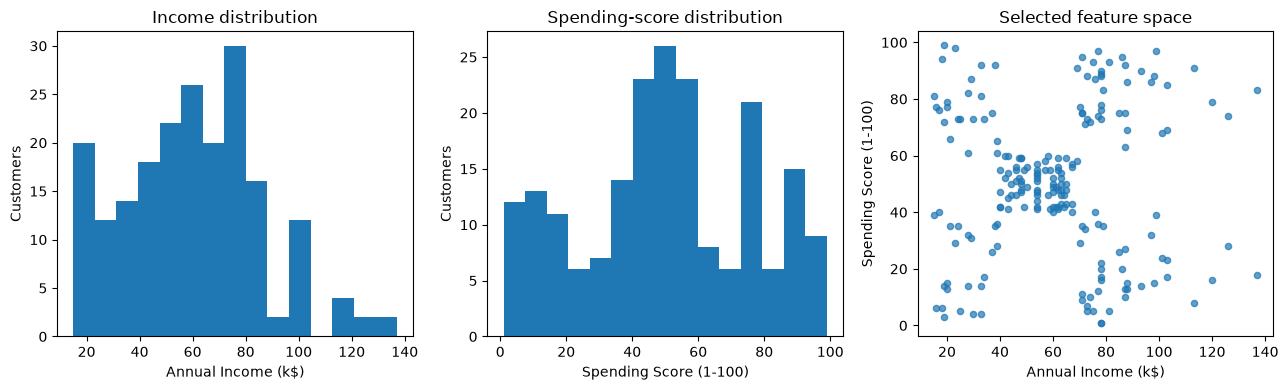

Selected-feature correlation:


,Annual Income (k$),Spending Score (1-100)
Annual Income (k$),1.000000,0.009903
Spending Score (1-100),0.009903,1.000000


In [5]:
fig, axes = plt.subplots(1,3,figsize=(13,4))
X[FEATURES[0]].plot.hist(bins=15,ax=axes[0])
axes[0].set(xlabel=FEATURES[0],ylabel="Customers",title="Income distribution")
X[FEATURES[1]].plot.hist(bins=15,ax=axes[1])
axes[1].set(xlabel=FEATURES[1],ylabel="Customers",title="Spending-score distribution")
axes[2].scatter(X[FEATURES[0]],X[FEATURES[1]],s=20,alpha=.7)
axes[2].set(xlabel=FEATURES[0],ylabel=FEATURES[1],title="Selected feature space")
fig.tight_layout()
fig.savefig(REPORTS / "feature_exploration.png",dpi=130)
plt.show()
print("Selected-feature correlation:")
display(X.corr())

## 7. Mine the data: fit and select K-Means

Fit the fixed candidates and record cluster sizes and convergence. Select by the
predeclared rule in standardized space, then retain that fitted pipeline. Inertia
naturally declines with more clusters; it cannot by itself select `k`. Save all
candidate diagnostics, not just the chosen result.

Convergence below the iteration cap establishes termination under a numerical
criterion, not the global optimum or substantive validity. Archive the original
reference fit. The sensitivity diagnostics below do not replace it with a more
favorable geometry or k after inspecting outcomes.

Verification refits every original candidate and recomputes its indices and
sizes, then checks the runner-up and sensitivity choices. Numerical reproducibility
of a local minimum is distinct from evidence of substantive knowledge. Initialization
agreement with 20 starts is not evidence that a single random start would be stable.

,k,inertia,smallest_cluster,largest_cluster,iterations,silhouette,davies_bouldin,calinski_harabasz,eligible
0,1,400.0000,200,200,2,NaN,NaN,NaN,False
1,2,269.6910,76,124,5,0.3213,1.2670,95.6694,True
2,3,157.7040,38,123,19,0.4666,0.7165,151.3351,True
3,4,108.9213,23,100,14,0.4939,0.7096,174.5952,True
4,5,65.5684,22,81,4,0.5547,0.5722,248.6493,True
5,6,55.0573,10,81,4,0.5399,0.6546,243.0879,True
6,7,44.8648,10,79,7,0.5281,0.7148,254.6212,True
7,8,37.1481,10,45,4,0.4567,0.7579,267.9142,True
8,9,32.3923,10,42,6,0.4571,0.7632,270.9484,True
9,10,29.6858,10,38,7,0.4362,0.7645,263.3497,True


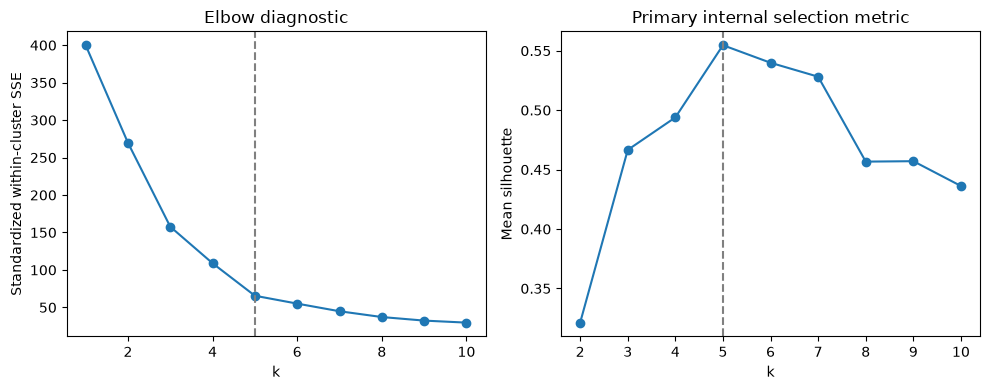

Selected k: 5
{'selected_k': 5, 'runner_up_k': 6, 'silhouette_gap_to_runner_up': 0.014777070432042794, 'davies_bouldin_best_k': 5, 'calinski_harabasz_best_k': 9, 'size_guard_excludes_any_k_2_to_10': False, 'interpretation': 'conditional silhouette optimum in the specified representation and candidate range, not true-k evidence'}


In [6]:
candidate_rows = []
models = {}
for k in range(1,11):
    candidate = make_pipeline(k,SEED).fit(X)
    models[k] = candidate
    transformed = candidate.named_steps["scale"].transform(X)
    labels = candidate.predict(X)
    sizes = np.bincount(labels,minlength=k)
    estimator = candidate.named_steps["kmeans"]
    assert estimator.n_iter_ < estimator.max_iter
    candidate_rows.append({"k":k,"inertia":float(estimator.inertia_),"smallest_cluster":int(sizes.min()),
                           "largest_cluster":int(sizes.max()),"iterations":int(estimator.n_iter_),
                           "silhouette":float(silhouette_score(transformed,labels)) if k>1 else None,
                           "davies_bouldin":float(davies_bouldin_score(transformed,labels)) if k>1 else None,
                           "calinski_harabasz":float(calinski_harabasz_score(transformed,labels)) if k>1 else None})
selection = pd.DataFrame(candidate_rows)
selection["eligible"] = selection.k.ge(2) & selection.smallest_cluster.ge(10)
eligible = selection[selection.eligible].sort_values(["silhouette","k"],ascending=[False,True])
assert not eligible.empty, "No candidate meets the declared size guard."
selected_k = int(eligible.iloc[0].k)
model = models[selected_k]
labels = model.predict(X)
scaled = model.named_steps["scale"].transform(X)
selection.to_csv(REPORTS / "cluster_selection.csv",index=False)
display(selection.round(4))
fig, axes = plt.subplots(1,2,figsize=(10,4))
axes[0].plot(selection.k,selection.inertia,"o-")
axes[0].axvline(selected_k,color="gray",linestyle="--")
axes[0].set(xlabel="k",ylabel="Standardized within-cluster SSE",title="Elbow diagnostic")
axes[1].plot(selection.k,selection.silhouette,"o-")
axes[1].axvline(selected_k,color="gray",linestyle="--")
axes[1].set(xlabel="k",ylabel="Mean silhouette",title="Primary internal selection metric")
fig.tight_layout()
fig.savefig(REPORTS / "cluster_selection.png",dpi=130)
plt.show()
print("Selected k:",selected_k)
runner_up = eligible.iloc[1]
selection_evidence = {"selected_k":selected_k,"runner_up_k":int(runner_up.k),
                      "silhouette_gap_to_runner_up":float(eligible.iloc[0].silhouette-runner_up.silhouette),
                      "davies_bouldin_best_k":int(selection.loc[selection.k.gt(1)].sort_values(["davies_bouldin","k"]).iloc[0].k),
                      "calinski_harabasz_best_k":int(selection.loc[selection.k.gt(1)].sort_values(["calinski_harabasz","k"],ascending=[False,True]).iloc[0].k),
                      "size_guard_excludes_any_k_2_to_10":bool((~selection.loc[selection.k.gt(1),"eligible"]).any()),
                      "interpretation":"conditional silhouette optimum in the specified representation and candidate range, not true-k evidence"}
(REPORTS / "selection_evidence.json").write_text(json.dumps(selection_evidence,indent=2)+"\n")
print(selection_evidence)


## 8. Interpret and evaluate the discovered patterns

Inspect cluster sizes, per-customer silhouettes, inverse-transformed centers, and
profiles in original units. Cluster numbers are arbitrary identifiers, not ranks;
segment descriptions refer to numeric centers rather than stereotyped customer
names. Age/gender summaries are descriptive associations, not inputs, explanations,
or a fairness certification. Differences in features used to form the groups are
expected by construction and are not independent statistical discoveries.

Refit with 10 seeds to check optimization sensitivity. Also refit the full pipeline
on 30 reproducible 80% subsamples without replacement, assigning all original records
with each refit and comparing against the reference using adjusted Rand index (ARI).
ARI is permutation-invariant. This is a perturbation diagnostic that includes
in-sample records, not held-out generalization, a confidence interval, or validation
of natural customer types. All refitted scalers learn only from their subsample.
No external segment labels or independent replication are available.

**Observed profiles for this fitted version.** Cluster 0 is the largest group:
81 customers (40.5%), with mean income 55.30 k$ and score 49.52. Higher-income
clusters 1 and 3 have similar mean income (86.54 and 88.20 k$) but different mean
scores (82.13 and 17.11). Lower-income clusters 2 and 4 similarly differ in mean
score (79.36 versus 20.91). Income alone therefore does not summarize the spending
score patterns in this sample. These comparisons concern the variables used to
construct the clusters; they do not establish why customers behave differently.

**Separate perturbations.** Keep optimizer seed 42 fixed for subsampling; changing
both seed and rows would conflate two causes. Also report ARI on the 40 omitted
rows per refit, not just all 200 records. The reference partition was itself fitted
to all rows, so omitted-row agreement is still a perturbation diagnostic, not an
independent external test or evidence of the true number of clusters.

Match reference and refitted labels one-to-one by maximizing overlap, then report
per-reference-cluster Jaccard over the 30 subsamples. This uses all original records
and complements rather than replaces omitted-row ARI. Shared reference, overlapping
subsamples and only 40 omitted records per replicate limit interpretation: neither
ARI nor Jaccard is accuracy against ground truth, independent replication, or a
confidence interval for population stability.

**Review evidence.** Five is reselected in all ten small subsample searches within
the original geometry, but halving score's squared-distance weight selects seven.
The rank-score diagnostic selects five with ARI 0.915 to the primary partition.
Thus cluster-count stability under sampling does not imply invariance to the
measurement model. Fixed-seed all-row/omitted-row ARIs average 0.989/0.985; the
minimum matched cluster Jaccard is 0.955. These are favorable limited perturbation
results, not validation of score semantics, real customer types or marketing value.

,customers,income_mean,income_median,score_mean,score_median,age_median,female_fraction,silhouette_mean,share
cluster,,,,,,,,,
0,81,55.296,54.0,49.519,50.0,46.0,0.593,0.598,0.405
1,39,86.538,79.0,82.128,83.0,32.0,0.538,0.511,0.195
2,22,25.727,24.5,79.364,77.0,23.5,0.591,0.598,0.110
3,35,88.200,85.0,17.114,16.0,42.0,0.457,0.505,0.175
4,23,26.304,25.0,20.913,17.0,46.0,0.609,0.511,0.115


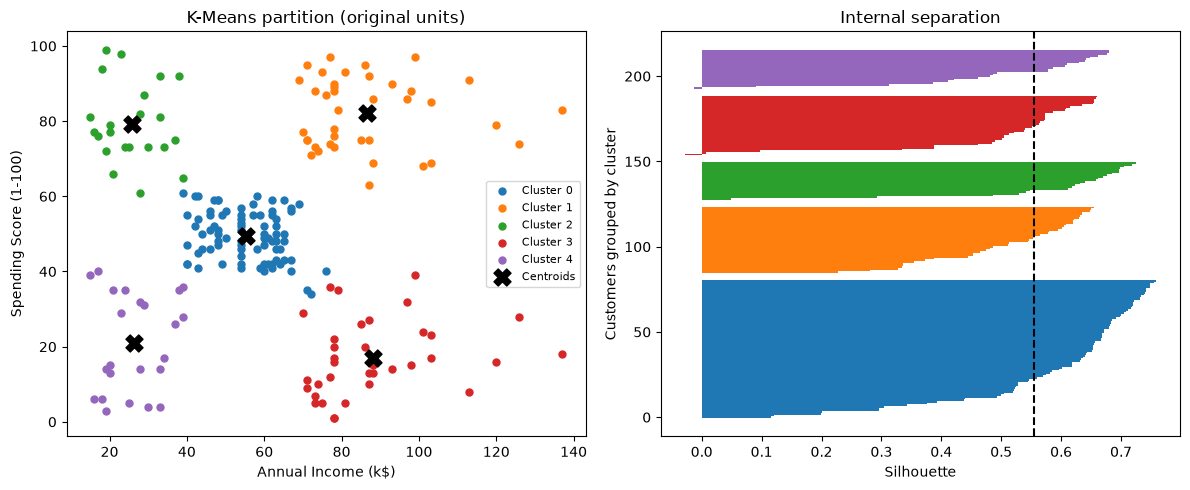

,mean,min,max
check,,,
initialization,1.00000,1.00000,1.0
subsample_80pct,0.98922,0.95793,1.0


{
  "rows": 200,
  "features": [
    "Annual Income (k$)",
    "Spending Score (1-100)"
  ],
  "selected_k": 5,
  "selection_rule": "highest silhouette for k=2..10 with minimum cluster size 10; smaller-k tie break",
  "silhouette": 0.5546571631111091,
  "davies_bouldin": 0.5722356162263351,
  "calinski_harabasz": 248.64932001536357,
  "inertia": 65.56840815571681,
  "smallest_cluster": 22,
  "negative_silhouette_customers": 2,
  "initialization_ari_mean": 1.0,
  "subsample_ari_mean": 0.9892204572640265,
  "omitted_subsample_ari_mean": 0.9854026349084279,
  "subsample_ari_min": 0.9579302764297815
}


,scenario,selected_k,selected_silhouette,fixed_primary_k,fixed_k_ari_to_primary,selected_k_ari_to_primary
0,score_weight_0.5,7,0.534565,5,0.969614,0.882136
1,score_weight_1,5,0.554657,5,1.000000,1.000000
2,score_weight_2,5,0.559908,5,0.971182,0.971182
3,score_rank_equal_weight,5,0.535999,5,0.914925,0.914925


,mean,min
reference_cluster,,
0,0.991016,0.963855
1,1.000000,1.000000
2,0.997036,0.954545
3,0.986111,0.972222
4,0.992754,0.956522


Reselected k frequencies: {5: 10}


710

In [7]:
silhouettes = silhouette_samples(scaled,labels)
centers = model.named_steps["scale"].inverse_transform(model.named_steps["kmeans"].cluster_centers_)
centroids = pd.DataFrame(centers,columns=FEATURES).rename_axis("cluster")
centroids.to_csv(REPORTS / "centroids.csv")
assignments = raw.assign(cluster=labels,silhouette=silhouettes)
assignments.to_csv(OUTPUTS / "cluster_assignments.csv",index=False)
profiles = assignments.groupby("cluster").agg(
    customers=("CustomerID","size"), income_mean=(FEATURES[0],"mean"), income_median=(FEATURES[0],"median"),
    score_mean=(FEATURES[1],"mean"), score_median=(FEATURES[1],"median"),
    age_median=("Age","median"), female_fraction=("Gender",lambda x:float(x.eq("Female").mean())),
    silhouette_mean=("silhouette","mean"))
profiles["share"] = profiles.customers / len(raw)
profiles.to_csv(REPORTS / "cluster_profiles.csv")
display(profiles.round(3))
fig, axes = plt.subplots(1,2,figsize=(12,5))
colors = plt.get_cmap("tab10")
y_start = 0
for cluster in range(selected_k):
    mask = labels==cluster
    axes[0].scatter(X.loc[mask,FEATURES[0]],X.loc[mask,FEATURES[1]],s=25,color=colors(cluster),label=f"Cluster {cluster}")
    values = np.sort(silhouettes[mask])
    axes[1].barh(np.arange(y_start,y_start+len(values)),values,height=1,color=colors(cluster))
    y_start += len(values)+4
axes[0].scatter(centers[:,0],centers[:,1],marker="X",s=150,color="black",label="Centroids")
axes[0].set(xlabel=FEATURES[0],ylabel=FEATURES[1],title="K-Means partition (original units)")
axes[0].legend(fontsize=8)
axes[1].axvline(silhouettes.mean(),color="black",linestyle="--")
axes[1].set(xlabel="Silhouette",ylabel="Customers grouped by cluster",title="Internal separation")
fig.tight_layout()
fig.savefig(REPORTS / "customer_segments.png",dpi=130)
plt.show()
stability = []
cluster_stability_rows = []
subsample_k_rows = []
for seed in range(10):
    refitted = make_pipeline(selected_k,seed).fit(X)
    stability.append({"check":"initialization","replicate":seed,"fit_rows":len(X),
                      "ari":float(adjusted_rand_score(labels,refitted.predict(X)))})
rng = np.random.default_rng(SEED)
for repeat in range(30):
    rows = rng.choice(len(X),size=int(.8*len(X)),replace=False)
    subset = X.iloc[rows]
    refitted = make_pipeline(selected_k,SEED).fit(subset)
    np.testing.assert_allclose(refitted.named_steps["scale"].mean_,subset.mean())
    predicted = refitted.predict(X)
    counts = contingency_matrix(labels,predicted)
    reference_ids,refit_ids = linear_sum_assignment(-counts)
    for reference_id,refit_id in zip(reference_ids,refit_ids):
        intersection = counts[reference_id,refit_id]
        union = counts[reference_id,:].sum()+counts[:,refit_id].sum()-intersection
        cluster_stability_rows.append({"replicate":repeat,"reference_cluster":int(reference_id),
                                       "matched_refit_cluster":int(refit_id),"jaccard":float(intersection/union)})
    if repeat < 10:
        for count in range(2,11):
            diagnostic = refitted if count==selected_k else make_pipeline(count,SEED).fit(subset)
            sub_labels = diagnostic.predict(subset)
            sub_matrix = diagnostic.named_steps["scale"].transform(subset)
            minimum = int(np.bincount(sub_labels,minlength=count).min())
            guard = int(np.ceil(.05*len(subset)))
            subsample_k_rows.append({"replicate":repeat,"k":count,"fit_rows":len(subset),
                                     "size_guard":guard,"smallest_cluster":minimum,"eligible":minimum>=guard,
                                     "silhouette":float(silhouette_score(sub_matrix,sub_labels))})
    omitted = np.setdiff1d(np.arange(len(X)),rows)
    predicted_all = refitted.predict(X)
    stability.append({"check":"subsample_80pct","replicate":repeat,"fit_rows":len(subset),
                      "ari":float(adjusted_rand_score(labels,predicted_all)),
                      "omitted_rows":len(omitted),
                      "omitted_ari":float(adjusted_rand_score(labels[omitted],predicted_all[omitted]))})
stability = pd.DataFrame(stability)
stability.to_csv(REPORTS / "stability.csv",index=False)
display(stability.groupby("check").ari.agg(["mean","min","max"]))
metrics = {"rows":len(raw),"features":FEATURES,"selected_k":selected_k,
           "selection_rule":"highest silhouette for k=2..10 with minimum cluster size 10; smaller-k tie break",
           "silhouette":float(silhouette_score(scaled,labels)),
           "davies_bouldin":float(davies_bouldin_score(scaled,labels)),
           "calinski_harabasz":float(calinski_harabasz_score(scaled,labels)),
           "inertia":float(model.named_steps["kmeans"].inertia_),
           "smallest_cluster":int(profiles.customers.min()),
           "negative_silhouette_customers":int((silhouettes<0).sum()),
           "initialization_ari_mean":float(stability.loc[stability.check.eq("initialization"),"ari"].mean()),
           "subsample_ari_mean":float(stability.loc[stability.check.eq("subsample_80pct"),"ari"].mean()),
           "omitted_subsample_ari_mean":float(stability.loc[stability.check.eq("subsample_80pct"),"omitted_ari"].mean()),
           "subsample_ari_min":float(stability.loc[stability.check.eq("subsample_80pct"),"ari"].min())}
(REPORTS / "metrics.json").write_text(json.dumps(metrics,indent=2)+"\n")
print(json.dumps(metrics,indent=2))
sensitivity_candidates,sensitivity = representation_sensitivity(X,labels,selected_k,include_rank=True)
sensitivity_candidates.to_csv(REPORTS / "sensitivity_candidates.csv",index=False)
sensitivity.to_csv(REPORTS / "representation_sensitivity.csv",index=False)
display(sensitivity)

cluster_stability = pd.DataFrame(cluster_stability_rows)
cluster_stability.to_csv(REPORTS / "cluster_stability.csv",index=False)
cluster_stability_summary = cluster_stability.groupby("reference_cluster").jaccard.agg(["mean","min"])
display(cluster_stability_summary)
subsample_k_candidates = pd.DataFrame(subsample_k_rows)
subsample_k_candidates.to_csv(REPORTS / "subsample_k_candidates.csv",index=False)
k_stability = (subsample_k_candidates[subsample_k_candidates.eligible]
               .sort_values(["replicate","silhouette","k"],ascending=[True,False,True])
               .groupby("replicate",as_index=False).first())
k_stability.to_csv(REPORTS / "k_stability.csv",index=False)
print("Reselected k frequencies:",k_stability.k.value_counts().sort_index().to_dict())
q1,q3 = X[FEATURES[0]].quantile([.25,.75]); iqr=q3-q1
retained = X[FEATURES[0]].between(q1-1.5*iqr,q3+1.5*iqr)
influence_model = make_pipeline(selected_k,SEED).fit(X.loc[retained])
quality_summary["income_iqr_exclusion_diagnostic"] = {
    "fit_rows":int(retained.sum()),"primary_rows_retained":len(X),"fixed_k":selected_k,
    "all_row_ari_to_primary":float(adjusted_rand_score(labels,influence_model.predict(X))),
    "interpretation":"fixed-k influence diagnostic only; no deletion from primary sample"}
(REPORTS / "quality_summary.json").write_text(json.dumps(quality_summary,indent=2)+"\n")
metrics["subsample_selected_k_counts"] = {str(int(k)):int(count) for k,count in k_stability.k.value_counts().items()}
metrics["per_cluster_jaccard_minimum"] = float(cluster_stability.jaccard.min())
(REPORTS / "metrics.json").write_text(json.dumps(metrics,indent=2)+"\n")


## 9. Use and communicate the knowledge

Publish the profiles, centroids, figures and source/parameter record as the practical
deliverable. Hypotheses for a mall analyst include testing whether customers near
different income/score centers respond differently to optional campaigns. Those
are proposed experiments, not established recommendations or causal effects.
There are no prior business rules supplied to reconcile with these patterns;
a domain owner should review score meaning, sampling and potential conflicts
before operational use. No campaigns or external messages are sent.

Demonstrate assigning **synthetic new profiles** by loading the saved pipeline.
It validates the two-column schema and uses the fitted scaler and nearest centroid.
Distances and gaps are descriptive, not confidence probabilities. K-Means always
assigns even an out-of-range profile; flag the included high-income extrapolation
example for review, rather than pretending the model detects new customer types.
Labels are meaningful only together with this version's centroid/profile mapping.
Only load trusted joblib files; keep `src/mall.py` available for serialized functions.

The range flag checks only the coordinate-wise training bounds: points inside the
box can still have weak support or be near a boundary. Distance gaps are not
calibrated probabilities or novelty detection. Acting on this study means publishing
a qualified description, not assigning benefits or exclusions to customer groups.
Without score metadata, sampling context and intervention outcomes, operational
marketing use is not supported.

The inside-box corner example (income 137 k$, score 99) illustrates that a false
range flag only means both coordinates lie within observed limits. It is not
acceptance of joint support or a calibrated confidence claim. Publish the
conditional findings with their metadata questions; obtain measurement definitions,
domain review and independent replication before using segments to guide offers.

In [8]:
model_path = OUTPUTS / "customer_segments.joblib"
joblib.dump(model,model_path)
loaded = joblib.load(model_path)
np.testing.assert_array_equal(loaded.predict(X),labels)
np.testing.assert_allclose(loaded.transform(X),model.transform(X),rtol=0,atol=0)
examples = pd.DataFrame({FEATURES[0]:[30,30,60,90,90,137,200],FEATURES[1]:[20,80,50,20,80,99,50]})
examples.to_csv(OUTPUTS / "example_profiles.csv",index=False)
demo = pd.concat([examples,assign_customers(loaded,examples,bounds)],axis=1)
demo.to_csv(REPORTS / "assignment_demo.csv",index=False)
display(demo)
assert demo.outside_training_range.iloc[-1]
assert not demo.outside_training_range.iloc[-2]  # Coordinate bounds do not measure joint support.
knowledge = {"purpose":"descriptive two-feature segmentation, not supervised prediction or causal marketing evidence",
             "selected_k":selected_k,"features":FEATURES,
             "findings":[{"cluster":int(cluster),"customers":int(row.customers),
                          "income_center_k_dollars":float(row.income_mean),"spending_score_center":float(row.score_mean)}
                         for cluster,row in profiles.iterrows()],
             "business_use":"numerical profiles for analyst review and prospective campaign hypotheses only",
             "finding_role":"summaries of the same supplied features used for construction, not independent behavioral validation",
             "representation_sensitivity":sensitivity.to_dict(orient="records"),
             "score_limitations":["formula and inputs unavailable", "interval distances unverified",
                                  "income/demographic dependence and cross-customer comparability unverified"],
             "unresolved":["sampling representativeness and scoring methodology", "temporal/external replication",
                           "no validated business/measurement basis for weighting despite limited sensitivity checks", "stakeholder usefulness and intervention benefit"]}
(REPORTS / "knowledge_summary.json").write_text(json.dumps(knowledge,indent=2)+"\n")
source = json.loads((PROJECT / "notebooks/mall_customers_kdd.ipynb").read_text())
code_source = "\n\n".join(c["source"] if isinstance(c["source"],str) else "".join(c["source"])
                          for c in source["cells"] if c["cell_type"]=="code")
packages = ["numpy","pandas","scipy","scikit-learn","matplotlib","joblib","nbformat","nbclient","ipykernel","jupyterlab"]
manifest = {"dataset":DATASET,"dataset_version":1,"source_url":SOURCE_URL,"download_url":DOWNLOAD_URL,
            "dataset_sha256":SHA256,"python":platform.python_version(),"packages":{p:version(p) for p in packages},
            "features":FEATURES,"seed":SEED,"selected_k":selected_k,"training_bounds":bounds,
            "parameters":{"n_init":20,"max_iter":300,"tol":1e-4,"algorithm":"lloyd","init":"k-means++"},
            "model_sha256":hashlib.sha256(model_path.read_bytes()).hexdigest(),
            "source_sha256":hashlib.sha256((PROJECT/"src/mall.py").read_bytes()).hexdigest(),
            "notebook_code_sha256":hashlib.sha256(code_source.encode()).hexdigest(),
            "validation_scope":"all-data internal diagnostics and perturbation stability, not external generalization",
            "stability_protocol":{"initialization_seeds":list(range(10)),"subsample_draw_seed":42,
                                  "subsample_optimizer_seed":42,"subsamples":30,"fraction":.8,
                                  "reselect_k_first_subsamples":10,"subsample_min_fraction":.05},
            "sensitivity_protocol":{"score_squared_distance_weights":[.5,1,2],"rank_score_diagnostic":True}}
(OUTPUTS / "run_manifest.json").write_text(json.dumps(manifest,indent=2)+"\n")
(PROJECT / "requirements.txt").write_text("# Python 3.11; verified direct versions, not a transitive lockfile.\n"+
                                       "".join(f"{p}=={version(p)}\n" for p in packages))
contract = {"columns":FEATURES,"income":"nonnegative finite number in source k$ units",
            "score":"finite number between 1 and 100","missing_values":"reject; no imputation",
            "extra_columns":"reject; exclude customer ID, age, gender",
            "extrapolation":"accepted within feature domain but flagged beyond observed training range",
            "assignment":"nearest standardized centroid; no probability or novelty detection"}
(REPORTS / "input_contract.json").write_text(json.dumps(contract,indent=2)+"\n")
print("Reloaded model reproduces all training assignments and centroid distances exactly.")
print(f"Selected {selected_k} clusters; internal silhouette {metrics['silhouette']:.3f}; subsampling ARI mean {metrics['subsample_ari_mean']:.3f}.")
assessment = {"technical_deliverable":"reproducible conditional two-feature partition",
              "primary_k":selected_k,"natural_customer_types_established":False,
              "five_clusters_claim":"conditional original-representation silhouette optimum; not an invariant or true count",
              "feature_selection_claim":"chosen income/score projection; no optimality or fairness certification",
              "evidence_limits":["weighting can alter preferred k", "all-data reference reused in stability checks",
                                 "score provenance and usefulness not validated"],
              "score_measurement_validated":False,"marketing_benefit_established":False,
              "use":"offline description and analyst hypotheses only",
              "required_before_action":["score formula, inputs and measurement comparability",
                                        "sampling frame, dates and income basis",
                                        "independent replication and stakeholder relevance",
                                        "consented prospective evaluation of intervention benefit"]}
(REPORTS / "assessment.json").write_text(json.dumps(assessment,indent=2)+"\n")


,Annual Income (k$),Spending Score (1-100),cluster,distance_to_centroid,distance_gap_to_second,outside_training_range
0,30,20,4,0.145446,1.353050,False
1,30,80,2,0.164948,1.362327,False
2,60,50,0,0.180508,1.426277,False
3,90,20,3,0.131418,1.620105,False
4,90,80,1,0.155830,1.620376,False
5,137,99,1,2.034411,1.628322,False
6,200,50,3,4.454224,0.052569,True


Reloaded model reproduces all training assignments and centroid distances exactly.
Selected 5 clusters; internal silhouette 0.555; subsampling ARI mean 0.989.


938

### Assumptions and remaining limitations

The income/score representation, standardization, size guard and candidate range
are study choices. The score's interval-scale interpretation is assumed for
Euclidean geometry; its underlying construction is unknown. Internal selection
and evaluation reuse the same 200 customers, so results are optimistic and do not
establish predictive accuracy, natural segments, or future customer behavior.
Initialization stability is not sampling stability, and neither proves business
utility. Distinct IDs do not establish independent sampling or population coverage.
The model cannot discover a novel segment during assignment and should be revisited
with dated, independently collected records and a validated business objective.
Direct dependencies are pinned; a fresh installation and full transitive lock are
not verified. No production scoring service or intervention benefit is demonstrated.